In [28]:
import pandas as pd
df = pd.read_csv(r"C:\Users\Admin\Downloads\online_retail_II.csv\online_retail_II.csv")
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


# Online Retail Dataset Analizi

## Dataset haqqında

Bu dataset onlayn retail (e-commerce) mağazasının satış məlumatlarını əhatə edir.  
Datasetdə məhsullar, müştərilər, sifarişlər və satış məlumatları yer alır.

Analizin əsas məqsədi:
- satış performansını analiz etmək,
- ən çox satılan məhsulları müəyyən etmək,
- müştəri davranışını araşdırmaq,
- ölkələr üzrə satışları müqayisə etmək,
- satış trendini analiz etmək
və ümumi biznes insight-ları əldə etməkdir.

---

# Sütunların izahı

| Sütun | Mənası |
|---|---|
| Invoice | Sifariş nömrəsi (transaction ID) |
| StockCode | Məhsulun unikal kodu |
| Description | Məhsulun adı |
| Quantity | Satılan məhsul sayı |
| InvoiceDate | Sifarişin tarixi və saatı |
| Price | Məhsulun 1 ədəd qiyməti |
| Customer ID | Müştərinin unikal ID-si |
| Country | Müştərinin yerləşdiyi ölkə |

---

# Analizin məqsədi

Bu analiz vasitəsilə aşağıdakı suallara cavab tapmaq məqsəd qoyulmuşdur:

- Şirkət ümumilikdə nə qədər gəlir əldə edib?
- Ən çox gəlir gətirən məhsullar hansılardır?
- Hansı ölkələrdə satış daha yüksəkdir?
- Müştərilərin alış davranışı necədir?
- Satışlar hansı aylarda və saatlarda daha çox olur?

---

# Analizin nəticəsində nə əldə olunacaq?

Analiz sonunda:
- satış performansı qiymətləndiriləcək,
- biznes üçün vacib insight-lar əldə olunacaq,
- müştəri və məhsul davranışı müəyyən ediləcək,
- gələcək satış strategiyaları üçün məlumat əldə olunacaq.

Bundan əlavə, dataset üzərində Machine Learning modeli qurularaq satış (Revenue) proqnozu da həyata keçirilmişdir.

In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 65.1 MB


In [30]:
df.shape

(1067371, 8)

In [31]:
df.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

Customer ID boş dəyərlərinin doldurulması

Qeyd: Customer ID sütunundakı boş dəyərlər satış qeydlərini qorumaq məqsədilə unikal Guest_ID dəyərləri ilə əvəz edilmişdir. Bu dəyişiklik yalnız məlumat itkisini azaltmaq üçün edilmişdir və real müştəri identifikasiyasını əks etdirmir.

Bu yanaşmanın məqsədi:

bütün satış qeydlərini datasetdə saxlamaq;
hər müştərinin unikal identifikatora malik olmasını təmin etmək;
müştəri əsaslı analizlərin aparılmasına imkan yaratmaq.

In [32]:
df["Customer ID"] = df["Customer ID"].fillna(
    pd.Series(
        [f"Guest_{i}" for i in range(df["Customer ID"].isnull().sum())],
        index=df[df["Customer ID"].isnull()].index
    )
)

In [33]:
df["Customer ID"].isnull().sum()

np.int64(0)

In [34]:
df = df.dropna(subset=["Description"])

In [35]:
df.duplicated().sum()
df = df.drop_duplicates()

In [36]:
df.duplicated().sum()
df = df.drop_duplicates()

## Qaytarılan məhsulların analizi

Bu analizdə qaytarılan məhsullar araşdırılmışdır.

Datasetdə `Quantity` sütununda mənfi (`< 0`) dəyərlər məhsulun geri qaytarıldığını göstərir. Buna görə ilk olaraq yalnız qaytarılmış məhsullar filtr edilmişdir.

Daha sonra məhsullar məhsul adına (`Description`) görə qruplaşdırılmış və hər məhsul üzrə ümumi qaytarılma sayı hesablanmışdır. Əldə olunan nəticələr sıralanaraq ən çox qaytarılan məhsullar müəyyən edilmişdir.

Nəticələrin daha aydın görünməsi üçün horizontal bar chart qurulmuşdur.

Bu analiz biznes baxımından vacibdir, çünki:
- problemli və ya keyfiyyətsiz məhsulları müəyyən etməyə kömək edir,
- müştəri narazılığı yaradan məhsulları göstərir,
- geri qaytarılma səbəblərini araşdırmaq üçün insight verir,
- satış və məhsul strategiyasını yaxşılaşdırmağa imkan yaradır.

Vizual nəticələr vasitəsilə ən çox refund olunan məhsullar aydın şəkildə müşahidə edilmişdir.

In [37]:
returns_df = df[df["Quantity"] < 0]

In [38]:
top_returns = returns_df.groupby("Description")["Quantity"].sum()

In [39]:
top_returns = top_returns.sort_values()

In [40]:
top_returns.head(10)

Description
PAPER CRAFT , LITTLE BIRDIE      -80995
MEDIUM CERAMIC TOP STORAGE JAR   -74494
?                                -37641
given away                       -20000
printing smudges/thrown away     -19200
missing                          -16467
Unsaleable, destroyed.           -15644
ebay sales                       -13630
check                            -13329
Given away                       -10200
Name: Quantity, dtype: int64

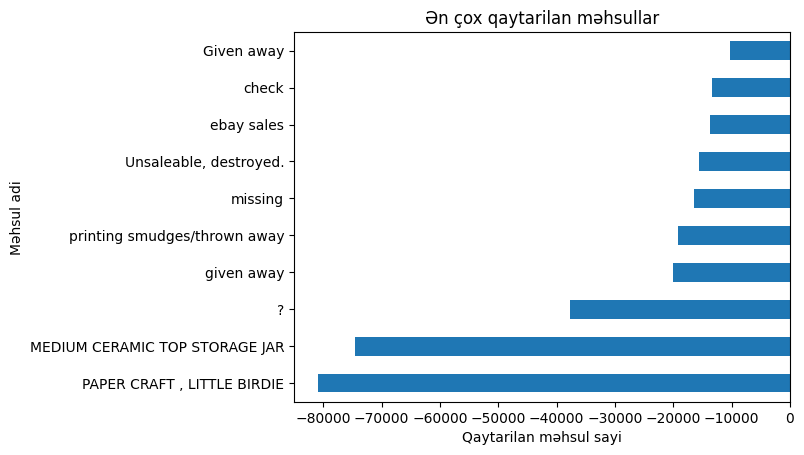

In [41]:
import matplotlib.pyplot as plt
top_returns.head(10).plot(kind="barh")
plt.title("Ən çox qaytarilan məhsullar")
plt.xlabel("Qaytarilan məhsul sayi")
plt.ylabel("Məhsul adi")
plt.show()

## Mənfi quantity dəyərlərinin silinməsi

Bu addımda `Quantity` sütununda mənfi dəyərə sahib olan sətirlər datasetdən silinmişdir.

Mənfi quantity dəyərləri əsasən qaytarılmış (refund edilmiş) sifarişləri göstərir. Satış analizini daha düzgün aparmaq üçün yalnız real satışlar saxlanılmışdır.

Beləliklə dataset satış analizinə uyğun təmizlənmişdir.

In [42]:
df = df[df["Quantity"] > 0]

## Cancel edilmiş sifarişlərin silinməsi

Bu addımda `Invoice` sütunu `C` hərfi ilə başlayan sifarişlər datasetdən silinmişdir.

Datasetdə `C` ilə başlayan invoice nömrələri cancel edilmiş və ya qaytarılmış sifarişləri göstərir. Analizin yalnız tamamlanmış satışlar üzərində aparılması üçün həmin məlumatlar çıxarılmışdır.

In [43]:
df = df[~df["Invoice"].astype(str).str.startswith("C")]

## Qiyməti 0 və ya mənfi olan dəyərlərin silinməsi

Bu addımda `Price` sütununda 0 və ya mənfi dəyərlərə sahib olan sətirlər datasetdən çıxarılmışdır.

Qiyməti 0 olan məhsullar real satış dəyəri daşımır və analiz nəticələrini səhv göstərə bilər. Buna görə yalnız düzgün və real qiymətə sahib satışlar saxlanılmışdır.

Bu addım data keyfiyyətini artırmaq və daha düzgün satış analizi aparmaq üçün edilmişdir.

In [44]:
df = df[df["Price"] > 0]

## Miqdar və Qiymət üzrə statistik analiz + Outlierlərin silinməsi

Bu mərhələdə əvvəlcə `Quantity` (miqdar) və `Price` (qiymət) sütunlarının minimum və maksimum dəyərləri yoxlanılmışdır. Bu, datasetdə qeyri-adi və ya səhv dəyərlərin olub-olmadığını anlamaq üçün edilir.

Daha sonra `Quantity` sütunu üçün IQR (Interquartile Range) metodu tətbiq olunmuşdur. Bu metod vasitəsilə:
- aşağı sərhəd (lower bound)
- yuxarı sərhəd (upper bound)

hesablanmış və bu aralıqdan kənarda qalan dəyərlər (outlier-lər) datasetdən çıxarılmışdır.

Bu addımın məqsədi:
- həddindən artıq böyük və ya kiçik dəyərlərin modeli və analizi pozmasının qarşısını almaq
- daha stabil və real nəticələr əldə etmək
- statistik analizlərin düzgün aparılmasını təmin etmək

Beləliklə dataset daha balanslı və analiz üçün uyğun hala gətirilmişdir.

In [45]:
# Miqdar (Quantity) üçün
print("Minimum Miqdar:", df["Quantity"].min())
print("Maksimum Miqdar:", df["Quantity"].max())

# Qiymət (Price) üçün
print("Minimum Qiymət:", df["Price"].min())
print("Maksimum Qiymət:", df["Price"].max())

Minimum Miqdar: 1
Maksimum Miqdar: 80995
Minimum Qiymət: 0.001
Maksimum Qiymət: 25111.09


In [46]:
Q1 = df["Quantity"].quantile(0.25)
Q3 = df["Quantity"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
df = df[(df["Quantity"] >= lower) & (df["Quantity"] <= upper)]

## Tarix (InvoiceDate) üzrə feature engineering

Bu mərhələdə `InvoiceDate` sütunu datetime formatına çevrilmiş və ondan yeni zaman əsaslı sütunlar yaradılmışdır.

`InvoiceDate` əvvəlcə string formatında olduğu üçün analiz üçün uyğun deyildi. Ona görə datetime formatına çevrilərək tarix üzərində əməliyyat aparmaq mümkün olmuşdur.

Daha sonra tarixdən aşağıdakı hissələr ayrılmışdır:
- Year (il)
- Month (ay)
- Day (gün)
- Hour (saat)

Bu transformasiyanın məqsədi:
- satışların zaman üzrə analizini aparmaq
- hansı il, ay, gün və saatda daha çox satış olduğunu müəyyən etmək
- trend və davranış analizini daha detallı etmək

Beləliklə dataset zaman baxımından daha analizə uyğun hala gətirilmişdir.

In [47]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [48]:
df["Year"] = df["InvoiceDate"].dt.year
df["Month"] = df["InvoiceDate"].dt.month
df["Day"] = df["InvoiceDate"].dt.day
df["Hour"] = df["InvoiceDate"].dt.hour

## Revenue sütununun yaradılması

Bu mərhələdə hər bir satış üzrə ümumi gəliri hesablamaq üçün yeni `Revenue` sütunu yaradılmışdır.

Revenue dəyəri `Quantity` (satılan məhsul sayı) ilə `Price` (bir məhsulun qiyməti) vurularaq hesablanır.

Bu transformasiyanın məqsədi:
- hər satışdan əldə olunan ümumi gəliri hesablamaq
- biznes analizi üçün əsas göstərici yaratmaq
- məhsul, müştəri və ölkə üzrə gəlir analizlərini aparmaq

Beləliklə datasetdə satışın real maliyyə dəyəri müəyyən edilmiş olur.

In [49]:
df["Revenue"] = df["Quantity"] * df["Price"]

In [50]:
df["Description"] = df["Description"].str.lower().str.strip()

In [51]:
df.info()

<class 'pandas.DataFrame'>
Index: 961904 entries, 0 to 1067370
Data columns (total 13 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      961904 non-null  str           
 1   StockCode    961904 non-null  str           
 2   Description  961904 non-null  str           
 3   Quantity     961904 non-null  int64         
 4   InvoiceDate  961904 non-null  datetime64[us]
 5   Price        961904 non-null  float64       
 6   Customer ID  961904 non-null  object        
 7   Country      961904 non-null  str           
 8   Year         961904 non-null  int32         
 9   Month        961904 non-null  int32         
 10  Day          961904 non-null  int32         
 11  Hour         961904 non-null  int32         
 12  Revenue      961904 non-null  float64       
dtypes: datetime64[us](1), float64(2), int32(4), int64(1), object(1), str(4)
memory usage: 88.1+ MB


In [52]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Year,Month,Day,Hour,Revenue
0,489434,85048,15cm christmas glass ball 20 lights,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,2009,12,1,7,83.4
1,489434,79323P,pink cherry lights,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009,12,1,7,81.0
2,489434,79323W,white cherry lights,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,2009,12,1,7,81.0
4,489434,21232,strawberry ceramic trinket box,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,2009,12,1,7,30.0
5,489434,22064,pink doughnut trinket pot,24,2009-12-01 07:45:00,1.65,13085.0,United Kingdom,2009,12,1,7,39.6


In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

## Ən çox gəlir gətirən məhsullar

Bu hissədə məhsullar `Description` sütununa görə qruplaşdırılmış və hər məhsul üzrə ümumi gəlir (`Revenue`) hesablanmışdır.

Nəticələr azalan sıraya düzülərək ən yüksək gəlir gətirən 10 məhsul seçilmişdir.

Daha sonra bu nəticə bar chart ilə vizuallaşdırılmışdır ki, ən çox gəlir gətirən məhsullar daha aydın görünsün.

Bu analiz şirkət üçün hansı məhsulların daha çox qazanc gətirdiyini müəyyən etməyə kömək edir.

In [54]:
top_products = df.groupby("Description")["Revenue"].sum().sort_values(ascending=False).head(10)
top_products

Description
manual                                336407.47
dotcom postage                        322657.48
regency cakestand 3 tier              213745.06
postage                               125342.42
white hanging heart t-light holder     91578.98
party bunting                          75360.11
assorted colour bird ornament          48766.66
jumbo bag red retrospot                48519.38
chocolate hot water bottle             47782.96
home building block word               45910.24
Name: Revenue, dtype: float64

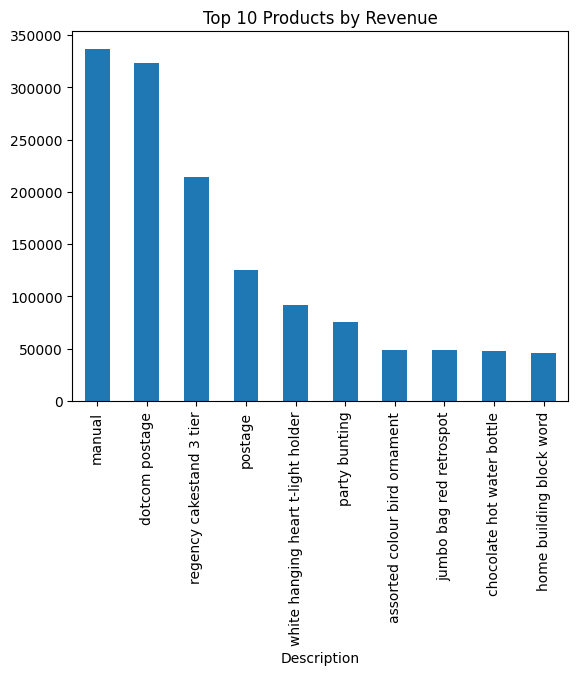

In [55]:
top_products.plot(kind="bar")
plt.title("Top 10 Products by Revenue")
plt.show()

## Ölkələr üzrə satış analizi

Bu mərhələdə satışlar `Country` sütununa görə qruplaşdırılmış və hər ölkə üzrə ümumi gəlir (`Revenue`) hesablanmışdır.

Nəticələr azalan sıraya düzülərək ən çox gəlir gətirən ölkələr müəyyən edilmişdir.

Daha sonra ilk 10 ölkə bar chart ilə vizuallaşdırılmışdır.

Bu analiz şirkətin hansı ölkələrdə daha çox satış etdiyini və əsas bazarlarının harada olduğunu göstərir.

In [56]:
country_sales = df.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
country_sales

Country
United Kingdom          1.167656e+07
EIRE                    3.737951e+05
Germany                 3.404380e+05
France                  2.682424e+05
Spain                   6.878084e+04
Switzerland             6.809369e+04
Netherlands             6.572609e+04
Belgium                 5.999348e+04
Portugal                4.705065e+04
Norway                  4.487957e+04
Channel Islands         3.345300e+04
Australia               3.169376e+04
Italy                   2.960551e+04
Sweden                  2.324194e+04
Finland                 2.269004e+04
Singapore               2.085556e+04
Cyprus                  2.068591e+04
Austria                 2.045674e+04
Denmark                 1.906412e+04
Hong Kong               1.801222e+04
Greece                  1.692461e+04
Unspecified             1.044771e+04
United Arab Emirates    9.836330e+03
Poland                  9.703350e+03
Israel                  8.540510e+03
Malta                   7.750880e+03
USA                     7.1222

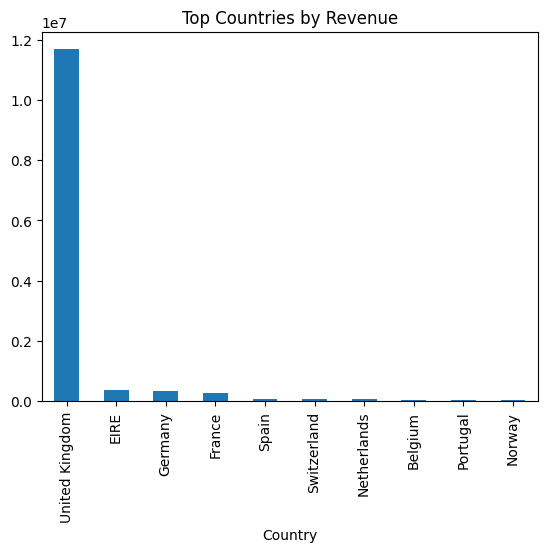

In [57]:
country_sales.head(10).plot(kind="bar")
plt.title("Top Countries by Revenue")
plt.show()

## Aylıq satış trendi

Bu mərhələdə `InvoiceDate` sütunu tarix formatına çevrilmiş və satışların aylıq analizini aparmaq üçün `Month` sütunu yaradılmışdır.

Daha sonra hər ay üzrə ümumi gəlir (`Revenue`) hesablanmış və satışların zaman üzrə dəyişimi analiz edilmişdir.

Nəticələr line chart ilə vizuallaşdırılmışdır ki, satışların aylara görə artıb-azalması daha aydın görünsün.

Bu analiz satışların zaman trendini və mövsümi dəyişiklikləri müəyyən etməyə kömək edir.

In [58]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["Month"] = df["InvoiceDate"].dt.to_period("M")
monthly_sales = df.groupby("Month")["Revenue"].sum()
monthly_sales

Month
2009-12    563992.940
2010-01    400849.092
2010-02    362427.336
2010-03    562726.671
2010-04    456417.782
2010-05    446787.580
2010-06    515078.170
2010-07    425468.000
2010-08    427049.840
2010-09    587344.531
2010-10    797245.820
2010-11    936050.502
2010-12    662088.630
2011-01    410080.220
2011-02    350032.520
2011-03    467556.730
2011-04    370746.991
2011-05    505339.770
2011-06    456250.470
2011-07    461884.821
2011-08    472924.890
2011-09    666834.892
2011-10    751846.130
2011-11    987849.610
2011-12    311443.560
Freq: M, Name: Revenue, dtype: float64

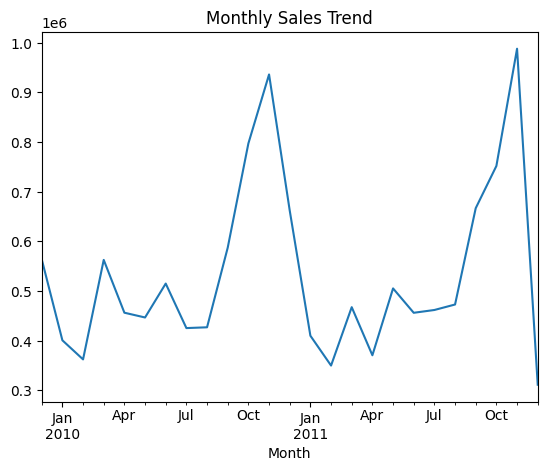

In [59]:
monthly_sales.plot(kind="line")
plt.title("Monthly Sales Trend")
plt.show()

## Saat üzrə satış analizi

Bu mərhələdə `InvoiceDate` sütunundan saat məlumatı çıxarılmış və `Hour` sütunu yaradılmışdır.

Daha sonra satışlar saatlara görə qruplaşdırılmış və hər saat üzrə ümumi gəlir (`Revenue`) hesablanmışdır.

Nəticələr bar chart ilə vizuallaşdırılmışdır ki, gün ərzində ən aktiv satış saatları aydın görünsün.

Bu analiz müştərilərin ən çox alış-veriş etdiyi saatları müəyyən etməyə kömək edir.

In [60]:
df["Hour"] = df["InvoiceDate"].dt.hour
hourly_sales = df.groupby("Hour")["Revenue"].sum()
hourly_sales

Hour
6           4.250
7       22618.080
8      306416.140
9     1050081.861
10    1461002.383
11    1548018.273
12    1885178.051
13    1780123.784
14    1740503.421
15    1668141.132
16    1019232.041
17     591554.702
18     185753.560
19      85262.720
20      12427.100
Name: Revenue, dtype: float64

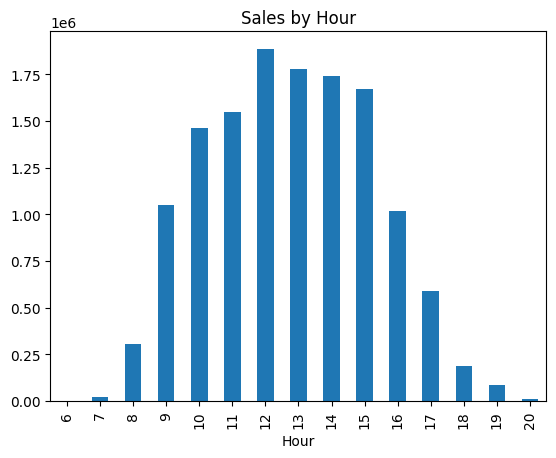

In [61]:
hourly_sales.plot(kind="bar")
plt.title("Sales by Hour")
plt.show()

## Müştərilər üzrə analiz

Bu mərhələdə satışlar `Customer ID` sütununa görə qruplaşdırılmış və hər müştərinin ümumi xərclədiyi məbləğ (`Revenue`) hesablanmışdır.

Nəticələr azalan sıraya düzülərək ən çox alış edən 10 müştəri müəyyən edilmişdir.

Daha sonra nəticə bar chart ilə vizuallaşdırılmışdır ki, ən dəyərli müştərilər daha aydın görünsün.

Bu analiz şirkət üçün ən yüksək gəlir gətirən müştəriləri müəyyən etməyə kömək edir.




In [62]:
top_customers = df.groupby("Customer ID")["Revenue"].sum().sort_values(ascending=False).head(10)
top_customers

Customer ID
14911.0    240107.79
14156.0     84613.73
13089.0     77666.03
17841.0     64944.91
14096.0     61295.62
17850.0     50623.87
14298.0     49390.33
15311.0     48897.87
14646.0     44900.10
13081.0     42544.74
Name: Revenue, dtype: float64

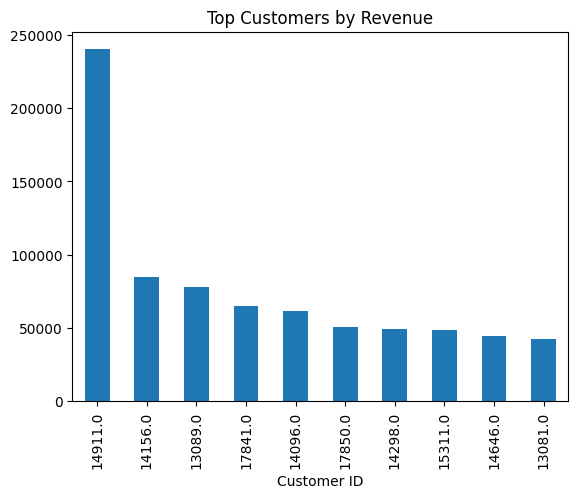

In [63]:
top_customers.plot(kind="bar")
plt.title("Top Customers by Revenue")
plt.show()

## Ümumi biznes göstəriciləri (KPI-lar)

Bu mərhələdə dataset üzrə əsas biznes göstəriciləri hesablanmışdır.

- `Total Revenue` → ümumi satış gəlirini göstərir və bütün alış-verişlərdən əldə olunan pulun cəmini ifadə edir.
- `Total Orders` → unikal sifarişlərin sayını göstərir (hər Invoice bir sifariş kimi qəbul edilir).
- `Total Customers` → şirkətin nə qədər fərqli müştəri ilə işlədiyini göstərir.

Bu göstəricilər ümumi biznes performansını qiymətləndirmək və şirkətin satış vəziyyətini anlamaq üçün istifadə olunur.

In [64]:
total_revenue = df["Revenue"].sum()
total_orders = df["Invoice"].nunique()
total_customers = df["Customer ID"].nunique()

print("Total Revenue:", total_revenue)
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)

Total Revenue: 13356317.498
Total Orders: 37547
Total Customers: 239473


## Satışın proqnozlaşdırılması (Linear Regression modeli)

Bu mərhələdə satış dəyərini (`Revenue`) proqnozlaşdırmaq üçün Machine Learning modeli qurulmuşdur.

İlk olaraq `Month` sütunu yaradılmış və model üçün input dəyişənlər seçilmişdir:
- Quantity (satış miqdarı)
- Price (qiymət)
- Month (ay)
- Hour (saat)

Bu dəyişənlər (`X`) müstəqil faktorlar, `Revenue` isə hədəf dəyişən (`y`) kimi istifadə edilmişdir.

Daha sonra dataset train və test hissələrinə bölünmüşdür ki, model bir hissədə öyrənsin, digər hissədə isə yoxlanılsın.

Linear Regression modeli yaradılmış və train datası ilə öyrədilmişdir.

Sonda model test datası üzərində işlədilərək satış gəliri (`Revenue`) proqnozlaşdırılmışdır.

Bu addımın məqsədi:
- satış dəyərini proqnozlaşdırmaq
- dəyişənlərin revenue üzərində təsirini öyrənmək
- sadə Machine Learning modeli qurmaq

Beləliklə, model gələcək satışların təxmini üçün istifadə oluna biləcək baza model rolunu oynayır.

In [65]:
df["Month"] = df["InvoiceDate"].dt.month

In [66]:
X = df[["Quantity", "Price", "Month", "Hour"]]
y = df["Revenue"]

In [67]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [68]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

In [69]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [70]:
y_pred = model.predict(X_test)

## Modelin qiymətləndirilməsi

Bu mərhələdə Linear Regression modelinin performansı müxtəlif metriklər vasitəsilə qiymətləndirilmişdir.

İstifadə olunan əsas göstəricilər:
- **MAE (Mean Absolute Error)** → proqnoz ilə real dəyər arasındakı orta mütləq xəta
- **MSE (Mean Squared Error)** → xətaların kvadratlarının ortası (böyük xətaları daha çox cəzalandırır)
- **RMSE (Root Mean Squared Error)** → MSE-nin kvadrat kökü, real vahidə daha yaxın nəticə verir
- **R² Score** → modelin izah edə bildiyi variasiya faizi (modelin nə qədər yaxşı işlədiyini göstərir)

Bu metriklər vasitəsilə modelin nə qədər düzgün proqnoz verdiyi və ümumi performansı qiymətləndirilmişdir.

In [71]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 6.465292691932414
MSE: 196.11534661015202
RMSE: 14.00411891588157
R2 Score: 0.9023374273767031


In [72]:
df.to_csv("cleaned_retail.csv", index=False)

In [73]:
df.shape

(961904, 13)